<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/day17_Bagging_RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick train.csv

Saving train.csv to train (1).csv


{'train (1).csv': b'school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,G3\n0,1,19,0,1,1,3,3,1,2,1,0,0,0,1,1,1,0,1,4,5,3,1,2,5,0,15,12,0,1,0,0,0,0,1,0,0,0,1,0,0,12\n1,0,18,1,1,1,2,3,2,1,0,0,1,1,0,1,1,1,1,5,2,3,1,2,4,0,11,10,0,0,0,0,0,0,1,0,0,0,0,0,0,10\n0,0,19,0,1,1,2,3,1,3,1,0,0,0,0,1,1,1,1,4,1,2,1,1,3,20,13,11,0,1,0,0,0,1,0,0,0,0,1,0,1,11\n0,1,15,1,1,1,4,3,1,2,0,0,1,1,1,1,1,1,0,4,3,3,2,3,5,6,9,9,0,0,0,1,0,1,0,0,1,0,0,1,0,10\n0,1,17,1,0,0,4,1,2,1,0,0,0,1,1,1,1,1,1,4,5,4,2,4,5,20,8,8,0,0,1,0,0,1,0,0,1,0,0,1,0,8\n1,0,18,1,0,1,3,1,1,2,0,0,1,1,0,1,1,1,0,4,3,4,1,1,1,0,7,9,0,0,0,1,0,0,1,0,0,0,0,1,0,8\n0,0,16,1,1,1,4,4,1,3,0,0,1,1,1,1,1,1,0,3,2,3,1,2,2,6,13,14,0,0,1,0,0,0,1,0,

In [4]:
# Cell 1: setup
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (RepeatedKFold, RepeatedStratifiedKFold, KFold,
                                     cross_validate, train_test_split)
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y = train["G3"]
y_risk = (y < 10).astype(int)
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

cv_reg = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)       # same folds as Day 16
cv_clf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
print("Training students:", len(train), "| features all:", X_all.shape[1], "| early:", X_early.shape[1])

Training students: 285 | features all: 41 | early: 39


In [5]:
# Cell 2: the bootstrap, seen directly
rng = np.random.default_rng(0)
n = len(train)
shares = [len(np.unique(rng.integers(0, n, n))) / n for _ in range(1000)]

print(f"Distinct students in a bootstrap sample (average of 1000): {np.mean(shares):.3f}")
print(f"Left out (the 'out-of-bag' students)                      : {1 - np.mean(shares):.3f}")
print(f"Theory, 1 - (1 - 1/n)^n                                   : {1 - (1 - 1/n) ** n:.3f}")

one_sample = rng.integers(0, n, n)
counts = np.bincount(one_sample, minlength=n)
print("\nIn one bootstrap sample, how many times does each student appear?")
print(pd.Series(counts).value_counts().sort_index().to_string())

Distinct students in a bootstrap sample (average of 1000): 0.634
Left out (the 'out-of-bag' students)                      : 0.366
Theory, 1 - (1 - 1/n)^n                                   : 0.633

In one bootstrap sample, how many times does each student appear?
0    105
1    108
2     49
3     15
4      7
6      1


In [6]:
# Cell 3: bagging from scratch
class BaggedTrees:
    def __init__(self, n_trees=100, max_depth=None, min_samples_leaf=1, seed=0):
        self.n_trees, self.max_depth = n_trees, max_depth
        self.min_samples_leaf, self.seed = min_samples_leaf, seed

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        rng = np.random.default_rng(self.seed)
        n = len(y)
        self.trees, self.in_bag = [], []
        for i in range(self.n_trees):
            idx = rng.integers(0, n, n)                       # bootstrap sample
            tree = DecisionTreeRegressor(max_depth=self.max_depth,
                                         min_samples_leaf=self.min_samples_leaf,
                                         random_state=i).fit(X[idx], y[idx])
            mask = np.zeros(n, dtype=bool)
            mask[idx] = True
            self.trees.append(tree)
            self.in_bag.append(mask)
        self.X_train, self.y_train = X, y
        return self

    def predict_all(self, X):                                  # one row of predictions per tree
        X = np.asarray(X, float)
        return np.array([t.predict(X) for t in self.trees])

    def predict(self, X):                                      # the ensemble: the average
        return self.predict_all(X).mean(axis=0)

    def oob_predict(self):
        preds = np.array([t.predict(self.X_train) for t in self.trees])
        out = np.where(~np.array(self.in_bag), preds, np.nan)  # keep only trees that did NOT see the student
        return np.nanmean(out, axis=0)

rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
print("BaggedTrees defined.")

BaggedTrees defined.


In [7]:
# Cell 4: does averaging help? Members vs the ensemble, and how many trees we need
sizes = [1, 3, 5, 10, 25, 50, 100, 200]
curve = {}
summary = []

for fname, X in feature_sets.items():
    Xv, yv = X.values, y.values
    member, ensemble, corr = [], [], []
    by_size = {b: [] for b in sizes}
    for tr, va in kf.split(Xv):
        bag = BaggedTrees(n_trees=200, seed=0).fit(Xv[tr], yv[tr])
        allp = bag.predict_all(Xv[va])                         # shape (200, validation students)
        member.append(np.mean([rmse(yv[va], p) for p in allp]))
        ensemble.append(rmse(yv[va], allp.mean(axis=0)))
        errs = allp - yv[va]
        c = np.corrcoef(errs)
        corr.append(c[np.triu_indices_from(c, k=1)].mean())
        for b in sizes:
            by_size[b].append(rmse(yv[va], allp[:b].mean(axis=0)))
    curve[fname] = {b: float(np.mean(v)) for b, v in by_size.items()}
    summary.append({"features": fname,
                    "avg single deep tree RMSE": round(np.mean(member), 3),
                    "ensemble of 200 RMSE": round(np.mean(ensemble), 3),
                    "avg error correlation between trees": round(np.mean(corr), 3)})

pd.DataFrame(summary)

,features,avg single deep tree RMSE,ensemble of 200 RMSE,avg error correlation between trees
0,early (no G1/G2),4.325,3.022,0.488
1,all features,1.298,0.916,0.500


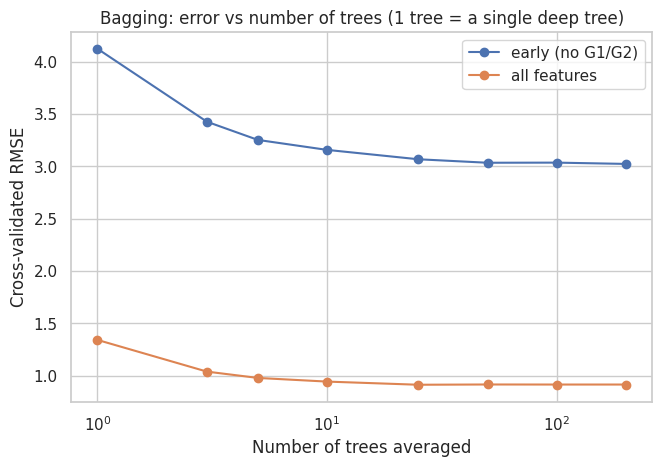

     early (no G1/G2)  all features
1               4.122         1.342
3               3.425         1.039
5               3.251         0.979
10              3.156         0.944
25              3.067         0.914
50              3.033         0.916
100             3.035         0.916
200             3.022         0.916


In [8]:
# Cell 5: plot the benefit of more trees
plt.figure(figsize=(7.5, 4.8))
for fname, c in curve.items():
    plt.plot(list(c), list(c.values()), "o-", label=fname)
plt.xscale("log")
plt.xlabel("Number of trees averaged"); plt.ylabel("Cross-validated RMSE")
plt.title("Bagging: error vs number of trees (1 tree = a single deep tree)")
plt.legend()
plt.savefig("bagging_curve.png", dpi=150, bbox_inches="tight")
plt.show()
print(pd.DataFrame(curve).round(3))

In [9]:
# Cell 6: the out-of-bag estimate, a free validation score
rows = []
for fname, X in feature_sets.items():
    bag = BaggedTrees(n_trees=300, seed=0).fit(X.values, y.values)
    oob = bag.oob_predict()
    rows.append({"features": fname,
                 "OOB RMSE (no hold-out used)": round(rmse(y, oob), 3),
                 "5-fold CV RMSE, 200 trees (Cell 4)": round(curve[fname][200], 3),
                 "training RMSE (flattering)": round(rmse(y, bag.predict(X.values)), 3)})
pd.DataFrame(rows)

,features,OOB RMSE (no hold-out used),"5-fold CV RMSE, 200 trees (Cell 4)",training RMSE (flattering)
0,early (no G1/G2),3.002,3.022,1.106
1,all features,0.914,0.916,0.337


In [10]:
# Cell 7: scikit-learn trees, bagging and Random Forests on the SAME folds as Day 16
def fold_rmse(model, X):
    r = cross_validate(model, X, y, cv=cv_reg, scoring="neg_root_mean_squared_error")
    return -r["test_score"]

configs = {
    "Baseline (mean)": DummyRegressor(),
    "Single tree (default)": DecisionTreeRegressor(random_state=42),
    "Bagging (max_features=1.0)": RandomForestRegressor(n_estimators=300, max_features=1.0,
                                                       random_state=42, n_jobs=-1),
    "Random Forest (max_features=0.33)": RandomForestRegressor(n_estimators=300, max_features=0.33,
                                                              random_state=42, n_jobs=-1),
    "Random Forest (sqrt)": RandomForestRegressor(n_estimators=300, max_features="sqrt",
                                                  random_state=42, n_jobs=-1),
    "Random Forest (0.33, leaf=5)": RandomForestRegressor(n_estimators=300, max_features=0.33,
                                                         min_samples_leaf=5, random_state=42, n_jobs=-1),
}

scores = {}
for fname, X in feature_sets.items():
    for mname, m in configs.items():
        scores[(fname, mname)] = fold_rmse(m, X)

rows = [{"features": f, "model": m, "RMSE": s.mean().round(3), "std": s.std().round(3)}
        for (f, m), s in scores.items()]
rf_table = pd.DataFrame(rows)
rf_table.pivot(index="model", columns="features", values="RMSE").loc[list(configs)]

features,all features,early (no G1/G2)
model,,
Baseline (mean),3.267,3.267
Single tree (default),1.237,4.354
Bagging (max_features=1.0),0.918,3.014
Random Forest (max_features=0.33),0.996,2.987
Random Forest (sqrt),1.370,2.985
"Random Forest (0.33, leaf=5)",1.100,2.993


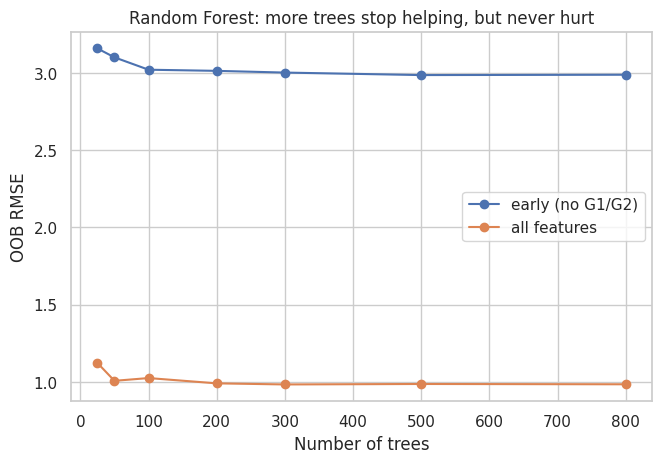

In [11]:
# Cell 8: how many trees are enough? (OOB error as the forest grows)
tree_counts = [25, 50, 100, 200, 300, 500, 800]
plt.figure(figsize=(7.5, 4.8))
for fname, X in feature_sets.items():
    rf = RandomForestRegressor(max_features=0.33, oob_score=True, warm_start=True,
                               random_state=42, n_jobs=-1)
    errs = []
    for t in tree_counts:
        rf.set_params(n_estimators=t)
        rf.fit(X, y)
        errs.append(rmse(y, rf.oob_prediction_))
    plt.plot(tree_counts, errs, "o-", label=fname)
plt.xlabel("Number of trees"); plt.ylabel("OOB RMSE")
plt.title("Random Forest: more trees stop helping, but never hurt")
plt.legend()
plt.savefig("rf_tree_count.png", dpi=150, bbox_inches="tight")
plt.show()

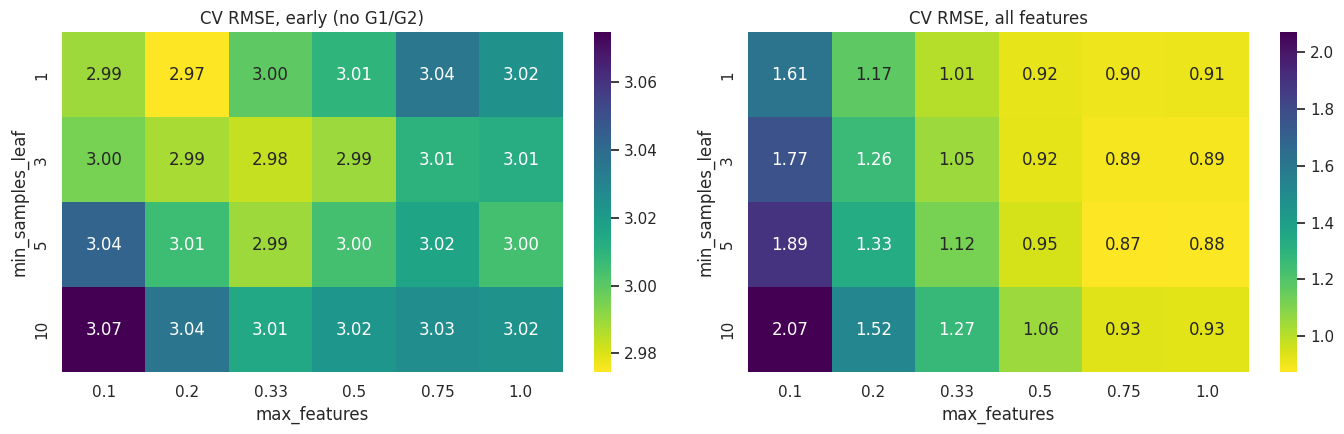

{'early (no G1/G2)': {'min_samples_leaf': 1, 'max_features': 0.2, 'cv_rmse': 2.974550913486241}, 'all features': {'min_samples_leaf': 5, 'max_features': 0.75, 'cv_rmse': 0.8746236234194574}}

Note: the winner is picked on the same folds that score it, so its number is a little
optimistic. Day 21 repeats the tuning inside nested cross-validation.


In [12]:
# Cell 9: max_features and min_samples_leaf (a single 5-fold run, to keep it quick)
mf_values = [0.1, 0.2, 0.33, 0.5, 0.75, 1.0]
leaf_values = [1, 3, 5, 10]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
best_cfg = {}
for ax, (fname, X) in zip(axes, feature_sets.items()):
    grid = pd.DataFrame(index=leaf_values, columns=mf_values, dtype=float)
    for leaf in leaf_values:
        for mf in mf_values:
            m = RandomForestRegressor(n_estimators=200, max_features=mf, min_samples_leaf=leaf,
                                      random_state=42, n_jobs=-1)
            r = cross_validate(m, X, y, cv=kf, scoring="neg_root_mean_squared_error")
            grid.loc[leaf, mf] = -r["test_score"].mean()
    sns.heatmap(grid.astype(float), annot=True, fmt=".2f", cmap="viridis_r", ax=ax)
    ax.set_title(f"CV RMSE, {fname}")
    ax.set_xlabel("max_features"); ax.set_ylabel("min_samples_leaf")
    best = grid.stack().idxmin()
    best_cfg[fname] = {"min_samples_leaf": int(best[0]), "max_features": float(best[1]),
                       "cv_rmse": float(grid.stack().min())}
plt.tight_layout()
plt.savefig("rf_grid.png", dpi=150, bbox_inches="tight")
plt.show()
print(best_cfg)
print("\nNote: the winner is picked on the same folds that score it, so its number is a little")
print("optimistic. Day 21 repeats the tuning inside nested cross-validation.")

In [13]:
# Cell 10: Random Forest vs Ridge vs the baseline, with paired folds
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40)))
rf_default = RandomForestRegressor(n_estimators=300, max_features=0.33, min_samples_leaf=3,
                                   random_state=42, n_jobs=-1)

rows = []
for fname, X in feature_sets.items():
    base = scores[(fname, "Baseline (mean)")]
    r_ridge = fold_rmse(ridge, X)
    r_rf = fold_rmse(rf_default, X)
    for mname, s in [("Ridge", r_ridge), ("Random Forest (0.33, leaf=3)", r_rf)]:
        gain = base - s
        rows.append({"features": fname, "model": mname,
                     "RMSE": round(s.mean(), 3), "std": round(s.std(), 3),
                     "gain over baseline %": round(100 * gain.mean() / base.mean(), 1),
                     "folds better than baseline": f"{(gain > 0).sum()}/{len(gain)}",
                     "folds RF beats Ridge": f"{(r_ridge - r_rf > 0).sum()}/{len(gain)}"
                                              if mname.startswith("Random") else ""})
final_cmp = pd.DataFrame(rows)
final_cmp

,features,model,RMSE,std,gain over baseline %,folds better than baseline,folds RF beats Ridge
0,early (no G1/G2),Ridge,2.966,0.130,9.2,15/15,
1,early (no G1/G2),"Random Forest (0.33, leaf=3)",2.980,0.149,8.8,15/15,9/15
2,all features,Ridge,0.903,0.082,72.4,15/15,
3,all features,"Random Forest (0.33, leaf=3)",1.038,0.074,68.2,15/15,0/15



early (no G1/G2)
  Top 6 by impurity importance   : ['absences', 'failures', 'health', 'Walc', 'studytime', 'age']
  Top 6 by permutation importance: ['schoolsup', 'absences', 'studytime', 'failures', 'Mjob_services', 'famsup']

all features
  Top 6 by impurity importance   : ['G2', 'G1', 'absences', 'failures', 'Walc', 'health']
  Top 6 by permutation importance: ['G2', 'G1', 'Walc', 'absences', 'failures', 'famrel']


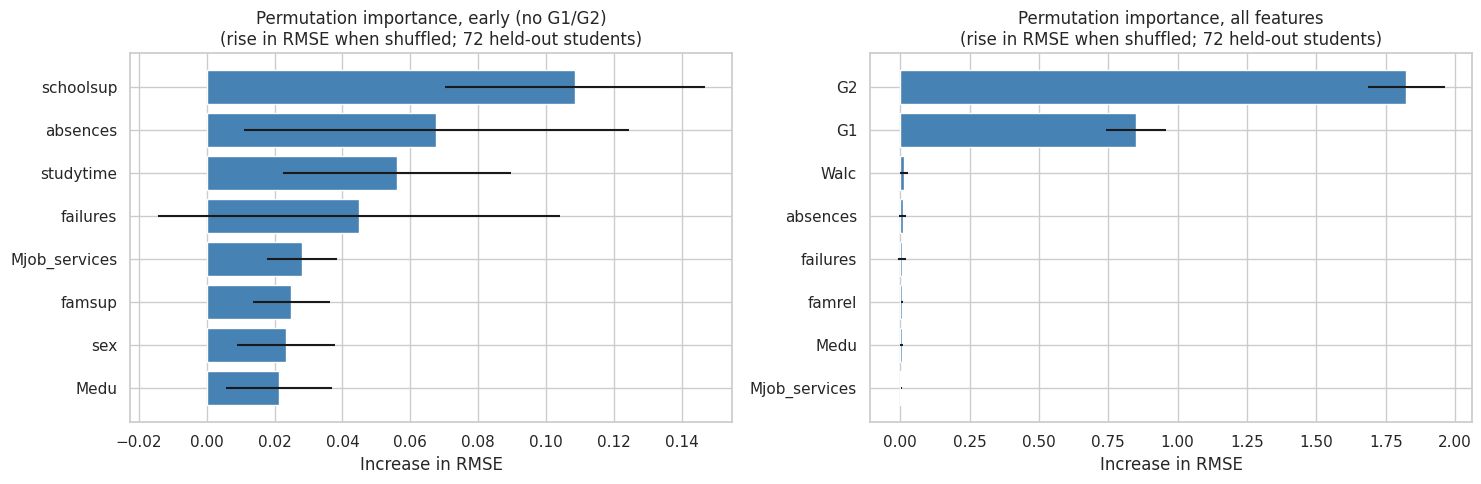

In [14]:
# Cell 11: feature importance, impurity vs permutation (permutation uses held-out students)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (fname, X) in zip(axes, [("early (no G1/G2)", X_early), ("all features", X_all)]):
    Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.25, random_state=0)
    rf = RandomForestRegressor(n_estimators=500, max_features=0.33, min_samples_leaf=3,
                               random_state=42, n_jobs=-1).fit(Xtr, ytr)
    imp = pd.Series(rf.feature_importances_, index=X.columns)
    perm = permutation_importance(rf, Xva, yva, n_repeats=30, random_state=0,
                                  scoring="neg_root_mean_squared_error")
    perm_mean = pd.Series(perm.importances_mean, index=X.columns)
    perm_std = pd.Series(perm.importances_std, index=X.columns)

    top = perm_mean.sort_values(ascending=False).head(8).index
    ax.barh(top[::-1], perm_mean[top][::-1], xerr=perm_std[top][::-1], color="steelblue")
    ax.set_title(f"Permutation importance, {fname}\n(rise in RMSE when shuffled; {len(Xva)} held-out students)")
    ax.set_xlabel("Increase in RMSE")

    print(f"\n{fname}")
    print("  Top 6 by impurity importance   :", list(imp.sort_values(ascending=False).head(6).index))
    print("  Top 6 by permutation importance:", list(perm_mean.sort_values(ascending=False).head(6).index))
plt.tight_layout()
plt.savefig("rf_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
# Cell 12: the same idea for the at-risk classifier (compare with Day 16 logistic regression)
rf_clf = RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=3,
                                random_state=42, n_jobs=-1)
rows = []
for fname, X in feature_sets.items():
    r = cross_validate(rf_clf, X, y_risk, cv=cv_clf, scoring={"auc": "roc_auc", "ap": "average_precision"})
    rows.append({"features": fname, "model": "Random Forest classifier",
                 "ROC AUC": round(r["test_auc"].mean(), 3), "AUC std": round(r["test_auc"].std(), 3),
                 "PR AUC": round(r["test_ap"].mean(), 3)})
rf_clf_table = pd.DataFrame(rows)

try:
    day16 = pd.read_csv("phase3_classification_results.csv")
    day16 = day16[day16.model == "Logistic"][["features", "model", "ROC AUC", "AUC std", "PR AUC"]]
    rf_clf_table = pd.concat([day16, rf_clf_table]).sort_values(["features", "model"])
except FileNotFoundError:
    print("(phase3_classification_results.csv not found, showing the forest only)")
rf_clf_table

(phase3_classification_results.csv not found, showing the forest only)


,features,model,ROC AUC,AUC std,PR AUC
0,early (no G1/G2),Random Forest classifier,0.663,0.059,0.428
1,all features,Random Forest classifier,0.952,0.030,0.882


In [16]:
# Cell 13: save results for Day 21
rf_table.to_csv("phase4_rf_regression_cv.csv", index=False)
final_cmp.to_csv("phase4_day17_comparison.csv", index=False)
rf_clf_table.to_csv("phase4_rf_classification.csv", index=False)
with open("rf_best_cfg_day17.json", "w") as f:
    json.dump(best_cfg, f, indent=2)
print("Saved. Best forest settings found (optimistic, re-tuned on Day 21):")
print(json.dumps(best_cfg, indent=2))

Saved. Best forest settings found (optimistic, re-tuned on Day 21):
{
  "early (no G1/G2)": {
    "min_samples_leaf": 1,
    "max_features": 0.2,
    "cv_rmse": 2.974550913486241
  },
  "all features": {
    "min_samples_leaf": 5,
    "max_features": 0.75,
    "cv_rmse": 0.8746236234194574
  }
}
